In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "abdallahalidev/plantvillage-dataset"
)

print(path)


Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
/kaggle/input/plantvillage-dataset


In [ ]:
selected_classes = [
    "Apple___Apple_scab",
    "Apple___healthy",
    "Potato___Early_blight",
    "Potato___healthy",
    "Tomato___Tomato_mosaic_virus"
]

print(selected_classes)

['Apple___Apple_scab', 'Apple___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Tomato___Tomato_mosaic_virus']


In [ ]:
from pathlib import Path

data_dir = Path(path) / "plantvillage dataset" / "color"

print(data_dir)

/kaggle/input/plantvillage-dataset/plantvillage dataset/color


In [ ]:
for class_name in selected_classes:
    class_dir = data_dir / class_name
    images = list(class_dir.glob("*"))
    print(class_name, ":", len(images), "images")

Apple___Apple_scab : 630 images
Apple___healthy : 1645 images
Potato___Early_blight : 1000 images
Potato___healthy : 152 images
Tomato___Tomato_mosaic_virus : 373 images


In [ ]:
import numpy as np
import PIL            # Load, manipulate, resize, crop, convert images
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

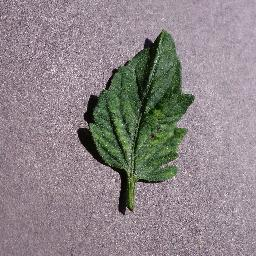

In [ ]:
tomato=list(data_dir.glob('Tomato___Tomato_mosaic_virus/*'))
PIL.Image.open(str(tomato[1]))

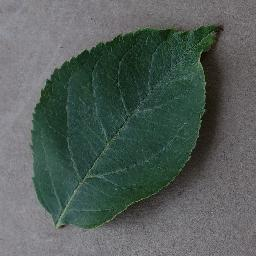

In [ ]:
healthy_apple=list(data_dir.glob('Apple___healthy/*'))
PIL.Image.open(str(healthy_apple[8]))

# **Model Training**

In [ ]:

batch_size=32
img_height=180
img_width=180

#seed=123 assures that same images goes to training and dev set every time we train the model
train_ds=tf.keras.utils.image_dataset_from_directory(
    data_dir,
    class_names=selected_classes,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(img_height,img_width),
    batch_size=batch_size
)

Found 3800 files belonging to 5 classes.
Using 3040 files for training.


In [ ]:
val_ds=tf.keras.utils.image_dataset_from_directory(
    data_dir,
    class_names=selected_classes,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(img_height,img_width),
    batch_size=batch_size
    )

Found 3800 files belonging to 5 classes.
Using 760 files for validation.


In [ ]:
class_names=train_ds.class_names
print(class_names)

['Apple___Apple_scab', 'Apple___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Tomato___Tomato_mosaic_virus']


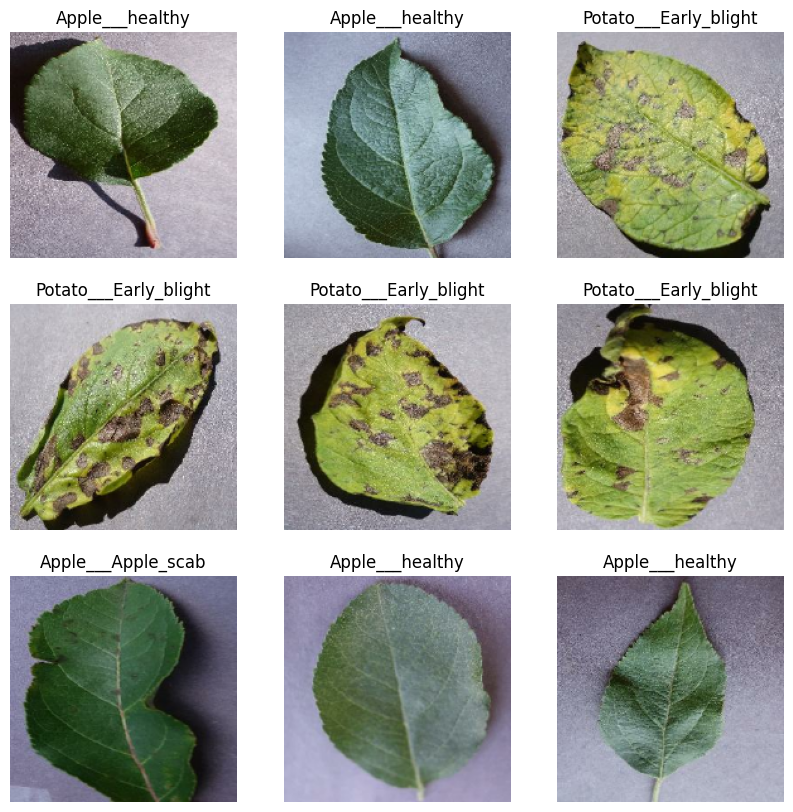

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
for image,label in train_ds.take(1):                     #take the 1st batch
  for i in range(9):                                     #take 9 images from 1st batch
    ax=plt.subplot(3,3,i+1)                              #subplot(rows, columns, position)
    plt.imshow(image[i].numpy().astype("uint8"))
    plt.title(class_names[label[i]])
    plt.axis("off")

In [ ]:
for image_batch, labels_batch in train_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break


(32, 180, 180, 3)
(32,)


In [ ]:
num_classes=len(class_names)
model = Sequential([
  layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.compile(optimizer="adam",
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,989,285 (15.22 MB)

 Trainable params: 3,989,285 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
epochs=10
history=model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

Epoch 1/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 35s 206ms/step - accuracy: 0.6997 - loss: 0.8831 - val_accuracy: 0.8934 - val_loss: 0.3280
Epoch 2/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 73ms/step - accuracy: 0.9138 - loss: 0.2555 - val_accuracy: 0.9355 - val_loss: 0.1953
Epoch 3/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step - accuracy: 0.9454 - loss: 0.1605 - val_accuracy: 0.9461 - val_loss: 0.1365
Epoch 4/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 8s 82ms/step - accuracy: 0.9615 - loss: 0.1052 - val_accuracy: 0.9474 - val_loss: 0.1670
Epoch 5/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.9651 - loss: 0.0944 - val_accuracy: 0.9553 - val_loss: 0.1290
Epoch 6/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.9783 - loss: 0.0599 - val_accuracy: 0.9382 - val_loss: 0.1981
Epoch 7/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 11s 77ms/step - accuracy: 0.9842 - loss: 0.0483 - val_accuracy: 0.9303 - val_loss: 0.2164
Epoch 8/10
95/95 ━━━━━━━━━━━━━━━━━━━━ 8s 54ms/step - accuracy: 0.9898 - loss: 0.0335 - val_accuracy: 0.9645

In [ ]:
acc=history.history["accuracy"]
val_acc=history.history["val_accuracy"]

loss=history.history["loss"]
val_loss=history.history["val_loss"]

epochs_range=range(epochs)

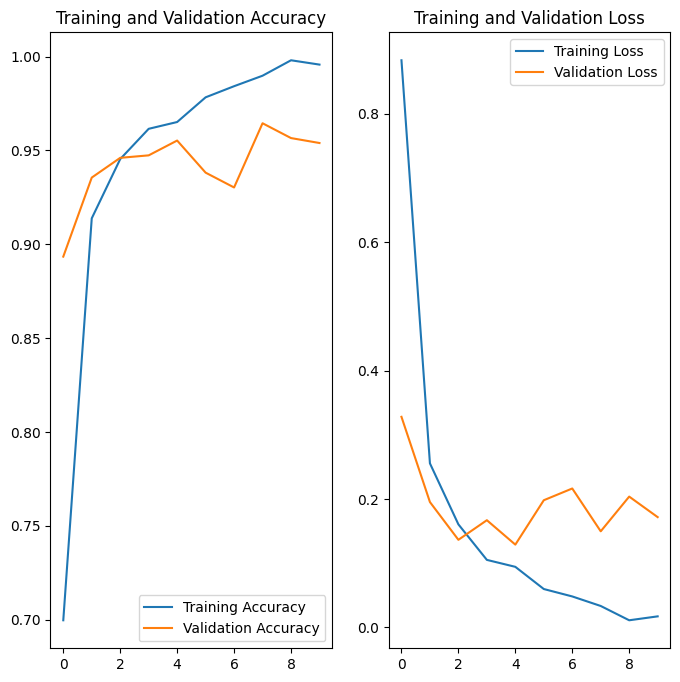

In [ ]:

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [ ]:
val_loss, val_accuracy = model.evaluate(val_ds)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)
best_val_accuracy = max(history.history["val_accuracy"])

print("Best Validation Accuracy:", best_val_accuracy)

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.9539 - loss: 0.1718
Validation Loss: 0.17182672023773193
Validation Accuracy: 0.9539473652839661
Best Validation Accuracy: 0.9644736647605896


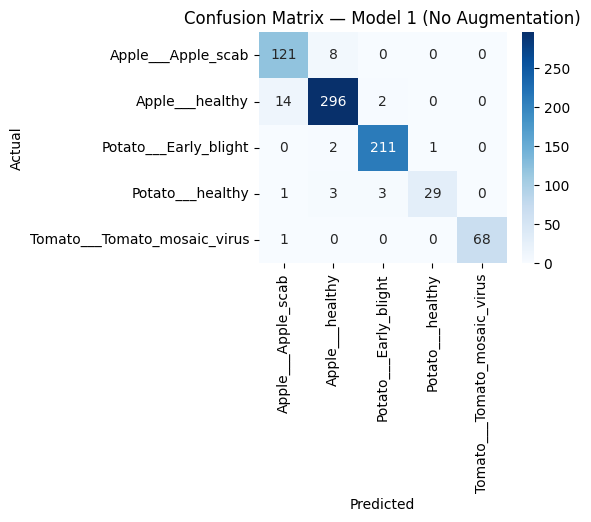

                              precision    recall  f1-score   support

          Apple___Apple_scab       0.88      0.94      0.91       129
             Apple___healthy       0.96      0.95      0.95       312
       Potato___Early_blight       0.98      0.99      0.98       214
            Potato___healthy       0.97      0.81      0.88        36
Tomato___Tomato_mosaic_virus       1.00      0.99      0.99        69

                    accuracy                           0.95       760
                   macro avg       0.96      0.93      0.94       760
                weighted avg       0.95      0.95      0.95       760



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true, y_pred = [], []
for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

y_true, y_pred = np.array(y_true), np.array(y_pred)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(4,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Model 1 (No Augmentation)')
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

As we can see in the graph the model was not overfitted so no need to apply overfitting techniques

Checking on real life image

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving test image.jpg to test image.jpg


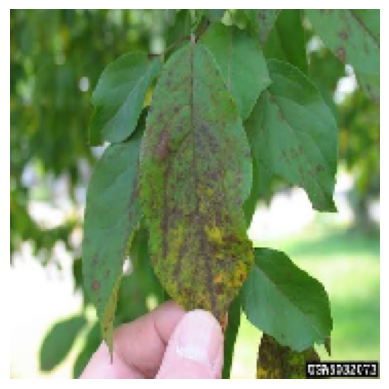

In [ ]:
test_image_path = "test image.jpg"

img = tf.keras.utils.load_img(
    test_image_path,
    target_size=(img_height, img_width)
)

plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

predictions = model.predict(img_array)

score = tf.nn.softmax(predictions[0])

predicted_class = class_names[np.argmax(score)]
confidence = 100 * np.max(score)

print("Predicted class:", predicted_class)
print("Confidence:", confidence, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted class: Potato___Early_blight
Confidence: 92.53141 %


In [ ]:
import numpy as np
from sklearn.metrics import classification_report
val_loss,val_acc=model.evaluate(val_ds)

y_true,y_pred=[],[]
for image,label in val_ds:
  preds=model.predict(image,verbose=0)
  y_true.extend(label.numpy())
  y_pred.extend(np.argmax(preds,axis=1))

report = classification_report(
    y_true, y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)
print(report)

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.9539 - loss: 0.1718
{'Apple___Apple_scab': {'precision': 0.8832116788321168, 'recall': 0.937984496124031, 'f1-score': 0.9097744360902256, 'support': 129.0}, 'Apple___healthy': {'precision': 0.9579288025889967, 'recall': 0.9487179487179487, 'f1-score': 0.9533011272141707, 'support': 312.0}, 'Potato___Early_blight': {'precision': 0.9768518518518519, 'recall': 0.985981308411215, 'f1-score': 0.9813953488372092, 'support': 214.0}, 'Potato___healthy': {'precision': 0.9666666666666667, 'recall': 0.8055555555555556, 'f1-score': 0.8787878787878788, 'support': 36.0}, 'Tomato___Tomato_mosaic_virus': {'precision': 1.0, 'recall': 0.9855072463768116, 'f1-score': 0.9927007299270073, 'support': 69.0}, 'accuracy': 0.9539473684210527, 'macro avg': {'precision': 0.9569317999879263, 'recall': 0.9327493110371124, 'f1-score': 0.9431919041712984, 'support': 760.0}, 'weighted avg': {'precision': 0.9548084069386925, 'recall': 0.9539473684210527, 'f1-score':

In [ ]:
import pandas as pd
result=pd.DataFrame([{
    "Model": "Custum CNN",
    "Val acc":val_acc,
    "Val loss":val_loss,
    "Best val acc":best_val_accuracy,
    "Macro F1": report["macro avg"]["f1-score"],
}])

In [ ]:
result.to_csv("custom_cnn_results.csv", index=False)
print(result)

        Model   Val acc  Val loss  Best val acc  Macro F1
0  Custum CNN  0.953947  0.171827      0.964474  0.943192
